# Toy 1 — Sine Regression: Comparing All 5 Parameter-Generator Families

This notebook is a Tier-1 validation exercise for the *Stochastic Surrogate
Constitutive Models* paper. Before trusting `pypolymix`'s five parameter
generators (`DeterministicGroup`, `IIDGaussianGroup`, `GaussianGroup`,
`LowRankGaussianGroup`, `LangevinGroup`) on the real, expensive,
GPU-only constitutive-model experiments, we run all five side by side on a
cheap 1D regression problem small enough to have a **known reference
posterior**, so that any bug in the ELBO/KL machinery shows up here first.

The notebook has two parts:

- **Part A** uses a `PolynomialChaosExpansion` surrogate with a *fixed, known*
  observation noise. Because a PCE is linear in its coefficients, this makes
  the true posterior an exact conjugate Gaussian, computable in closed form
  with plain linear algebra -- no grid, no MCMC. This is a strict,
  non-approximate "does the arithmetic work at all" check, intentionally on a
  simpler/well-conditioned problem than Part B, since its only job is
  correctness validation.
- **Part B** uses a small multi-layer neural network with the SiLU
  ("sigmoid-weighted linear") activation used by the real experts in the
  paper, scaled down. We pretrain it deterministically, freeze everything but
  the final layer, and run the four stochastic families plus the
  deterministic baseline on that small stochastic subset, using
  `WhitenedGroup.from_point_estimate` -- the exact partial-stochasticity +
  whitening recipe the real experiments use (`methodology.tex`,
  `sec:whitening`/`sec:partial`), with the same `relative_scale=0.1`,
  `sigma_min=1e-6` the real training configs use. Since a dense grid gives an
  "exact up to resolution" reference regardless of linearity, Part B keeps
  the same rigor as Part A while being architecturally representative of the
  real mixture-of-experts surrogate.

Runtime: every training run below is deliberately a full, properly-scheduled
fit (`OneCycleLR`, enough epochs to converge), not a shortened toy run --
sized for a trustworthy comparison, not for speed. The notebook is still
cheap enough (CPU, no GPU) to measure directly; see the final cell for the
actual wall-clock time of this run.

In [1]:
import time

_notebook_start = time.time()

In [2]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.distributions as td
import torch.nn.functional as F

from pypolymix.parameter_groups import (
    DeterministicGroup,
    GaussianGroup,
    IIDGaussianGroup,
    LangevinGroup,
    LowRankGaussianGroup,
    WhitenedGroup,
)
from pypolymix.parameter_groups.kl_estimators import (
    AnalyticKL,
    DiagonalGaussianEntropyKL,
    ReparamMonteCarloKL,
)
from pypolymix.priors import IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork, PolynomialChaosExpansion
from pypolymix import StochasticModel

torch.set_default_dtype(torch.float64)  # precision matters for the closed-form checks below

FAMILIES = ["deterministic", "iid", "full", "lowrank", "langevin"]
FAMILY_LABELS = {
    "deterministic": "Deterministic (MAP)",
    "iid": "Mean-field Gaussian",
    "full": "Full-covariance Gaussian",
    "lowrank": "Low-rank Gaussian",
    "langevin": "Langevin",
}
FAMILY_COLORS = {
    "deterministic": "tab:gray",
    "iid": "tab:blue",
    "full": "tab:green",
    "lowrank": "tab:orange",
    "langevin": "tab:red",
}

# Where the exported dat/*.txt tables for the paper's tikz/pgfplots pipeline go.
# pypolymix and the salt paper are separate repos; adjust this path if your
# checkout layout differs.
PAPER_DAT_DIR = pathlib.Path.home() / "projects/salt/doc/paper/stochastic_surrogates/dat"

## Part A — Closed-form validation on a small Polynomial Chaos Expansion

### Data and surrogate

A smooth two-frequency sine curve, observed with *known* Gaussian noise
`sigma_obs` (not learned here -- that's what makes the closed form possible).
We deliberately use a mild, well-conditioned problem (`x` spanning the full
`[-1, 1]` domain, as Legendre polynomials assume) so that gradient-based
training converges quickly and cleanly; this is distinct from the richer,
harder two-sided domain used by `full_covariance.ipynb`/`low_rank_covariance.ipynb`,
since Part A's only job is correctness validation, not a compelling fit.

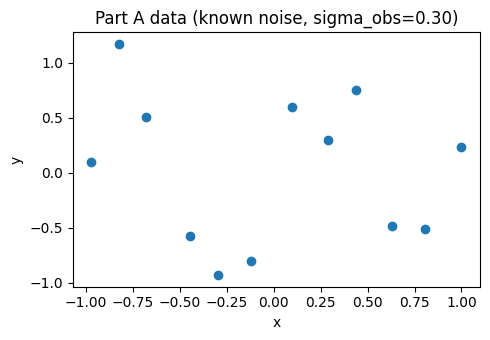

In [3]:
torch.manual_seed(0)

n_train_a = 12
sigma_obs_a = 0.3
sigma_prior_a = 1.0

x_train_a = torch.linspace(-1, 1, n_train_a).unsqueeze(-1) + 0.02 * torch.randn(n_train_a, 1)
x_train_a = x_train_a.clamp(-1, 1)
y_train_a = torch.sin(2 * torch.pi * x_train_a) + 0.3 * torch.sin(6 * torch.pi * x_train_a)
y_train_a = y_train_a + sigma_obs_a * torch.randn(n_train_a, 1)

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_train_a, y_train_a)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Part A data (known noise, sigma_obs=%.2f)" % sigma_obs_a)
plt.tight_layout()

### Closed-form reference posterior

A degree-5 `PolynomialChaosExpansion` (6 Legendre coefficients) is exactly
linear in its coefficients, `y = Phi @ c`, so with a Gaussian prior
`c ~ N(0, sigma_prior^2 I)` and the known noise above, the posterior over `c`
is the standard conjugate-Gaussian linear-regression result,

```
Sigma_post = (Phi^T Phi / sigma_obs^2 + I / sigma_prior^2)^{-1}
mu_post    = Sigma_post @ (Phi^T y) / sigma_obs^2
```

We extract the basis matrix `Phi` from the library's own `PolynomialChaosExpansion`
by evaluating it at the identity matrix (`PCE(x, I)[t, b] = Phi[b, t]`), so the
reference uses exactly the same basis the trained models do, not a
hand-rederived one.

In [4]:
degree_a = 5
surrogate_a = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=degree_a)
num_terms_a = surrogate_a.num_terms
print(f"PCE has {num_terms_a} coefficients")

with torch.no_grad():
    Phi_a = surrogate_a(x_train_a, torch.eye(num_terms_a)).squeeze(-1).T  # (n_train_a, num_terms_a)

cond_number = torch.linalg.cond(Phi_a.T @ Phi_a).item()
print(f"condition number of Phi^T Phi: {cond_number:.2f} (well-conditioned)")

prior_precision_a = torch.eye(num_terms_a) / sigma_prior_a**2
post_precision_a = Phi_a.T @ Phi_a / sigma_obs_a**2 + prior_precision_a
post_cov_a = torch.linalg.inv(post_precision_a)
post_mean_a = post_cov_a @ (Phi_a.T @ y_train_a.squeeze(-1)) / sigma_obs_a**2
true_posterior_a = td.MultivariateNormal(loc=post_mean_a, covariance_matrix=post_cov_a)

ols_a = torch.linalg.lstsq(Phi_a, y_train_a).solution.squeeze(-1)
print("closed-form posterior mean:", post_mean_a.numpy())
print("ordinary least squares    :", ols_a.numpy())
print("posterior std per coefficient:", torch.diagonal(post_cov_a).sqrt().numpy())

PCE has 6 coefficients
condition number of Phi^T Phi: 9.54 (well-conditioned)


closed-form posterior mean: [-0.02577018 -0.27962172  0.21600675 -0.82008994 -0.18912748  1.39568072]
ordinary least squares    : [-0.0281563  -0.29226031  0.21704277 -0.87808094 -0.20660979  1.49108947]
posterior std per coefficient: [0.08841527 0.14652538 0.18120388 0.20494824 0.21859577 0.23027741]


### Train all 5 families on the identical data/surrogate

Every family optimizes the same (unnormalized) ELBO,
`loss = sum_i NLL_i + KL(q || prior)` (the `pypolymix.elbo_loss` convention
`mean_NLL + KL/n_train` is equivalent up to the constant `n_train`; we use the
summed form here since it reads directly off the closed-form derivation
above). `DeterministicGroup` is included as a point-estimate / MAP baseline
for visual reference -- it has no distribution to compare a KL against.
`LangevinGroup` uses `DiagonalGaussianEntropyKL` (not the library's
collapse-prone `CrossEntropyOnly` default -- see
`kl_estimators_comparison.ipynb`) so this is a fair test of the *intended*
production configuration.

In [5]:
def make_group_a(kind):
    prior = IIDGaussianPrior(mean=0.0, std=sigma_prior_a)
    if kind == "deterministic":
        return DeterministicGroup("c", num_terms_a)
    if kind == "iid":
        return IIDGaussianGroup("c", num_terms_a, prior=prior)
    if kind == "full":
        return GaussianGroup("c", num_terms_a, prior=prior)
    if kind == "lowrank":
        return LowRankGaussianGroup("c", num_terms_a, rank=min(3, num_terms_a - 1), prior=prior)
    if kind == "langevin":
        score_model = NeuralNetwork(num_inputs=num_terms_a, num_outputs=num_terms_a, width=16, depth=2)
        return LangevinGroup(
            "c", num_terms_a, score_model=score_model, prior=prior,
            num_particles=64, num_diffusion_steps=60, step_size=1e-2, init_std=1.0,
            kl_estimator=DiagonalGaussianEntropyKL(),
        )
    raise ValueError(kind)


def train_a(kind, num_epochs=2000, num_samples=32, lr=1e-2, seed=1):
    torch.manual_seed(seed)
    group = make_group_a(kind)
    model = StochasticModel(surrogate_a, group)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    history = []
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = surrogate_a(x_train_a, params)
        target = y_train_a.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_a).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        optimizer.step()
        scheduler.step()
        if (epoch + 1) % 500 == 0:
            history.append((epoch + 1, loss.item()))
    return group, model, history

In [6]:
results_a = {}
for kind in FAMILIES:
    t0 = time.time()
    group, model, history = train_a(kind)
    results_a[kind] = {"group": group, "model": model, "history": history, "time": time.time() - t0}
    final_loss = history[-1][1] if history else float("nan")
    print(f"{FAMILY_LABELS[kind]:28s} trained in {results_a[kind]['time']:.1f}s, final loss={final_loss:.4f}")

Deterministic (MAP)          trained in 2.6s, final loss=10.3626


Mean-field Gaussian          trained in 2.4s, final loss=15.5701


Full-covariance Gaussian     trained in 13.7s, final loss=16.2025


Low-rank Gaussian            trained in 14.3s, final loss=16.3378


Langevin                     trained in 89.6s, final loss=17.0322


### Validation A1 — posterior mean/std vs the closed-form reference

For the three Gaussian families we read the fitted mean/covariance directly
off `variational_distribution()`. For Langevin (no explicit density) we
moment-match a Gaussian to its particle cloud, clearly flagged as an
approximation, not an exact `q`.

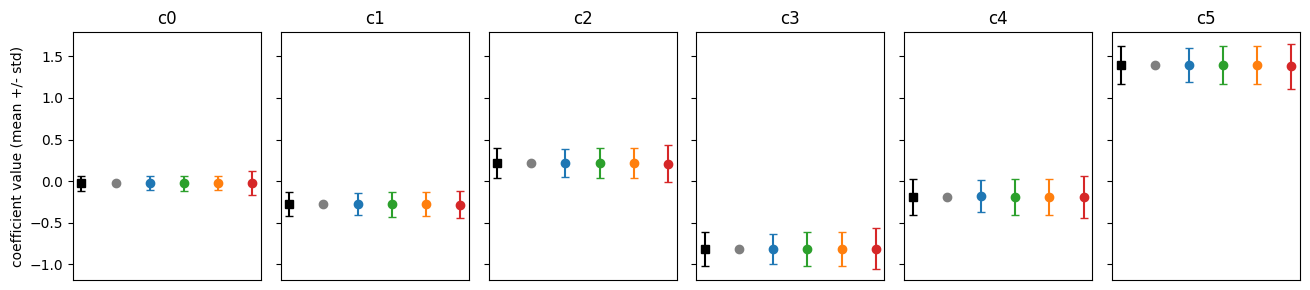

In [7]:
def fitted_moments_a(kind):
    group = results_a[kind]["group"]
    if kind == "deterministic":
        return group.params.detach().clone(), None
    if kind == "langevin":
        particles = group.sample_parameters(4000).detach()
        mean = particles.mean(0)
        cov = torch.cov(particles.T) + 1e-6 * torch.eye(num_terms_a)
        return mean, cov
    q = group.variational_distribution()
    mean = q.mean.detach()
    if kind == "iid":
        cov = torch.diag(q.variance.detach())
    else:
        cov = q.covariance_matrix.detach()
    return mean, cov


fig, axes = plt.subplots(1, num_terms_a, figsize=(2.2 * num_terms_a, 3), sharey=True)
coeff_idx = np.arange(num_terms_a)
for j, ax in enumerate(axes):
    ax.errorbar(
        [0], [post_mean_a[j].item()], yerr=[post_cov_a[j, j].sqrt().item()],
        fmt="ks", label="closed form", capsize=3,
    )
    for k, kind in enumerate(FAMILIES):
        mean, cov = fitted_moments_a(kind)
        yerr = [cov[j, j].sqrt().item()] if cov is not None else [0.0]
        ax.errorbar(
            [k + 1], [mean[j].item()], yerr=yerr, fmt="o", color=FAMILY_COLORS[kind], capsize=3,
        )
    ax.set_title(f"c{j}")
    ax.set_xticks([])
axes[0].set_ylabel("coefficient value (mean +/- std)")
plt.tight_layout()

In [8]:
kl_to_reference_a = {}
for kind in ["iid", "full", "lowrank"]:
    mean, cov = fitted_moments_a(kind)
    q_full = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
    kl_to_reference_a[kind] = td.kl_divergence(q_full, true_posterior_a).item()

mean, cov = fitted_moments_a("langevin")
q_langevin = td.MultivariateNormal(loc=mean, covariance_matrix=cov)
kl_to_reference_a["langevin"] = td.kl_divergence(q_langevin, true_posterior_a).item()

print("KL(q || closed-form true posterior), lower is better:")
for kind, kl in kl_to_reference_a.items():
    flag = "  (moment-matched approximation, not exact q)" if kind == "langevin" else ""
    print(f"  {FAMILY_LABELS[kind]:28s} {kl:8.4f} nats{flag}")

KL(q || closed-form true posterior), lower is better:
  Mean-field Gaussian            0.3055 nats
  Full-covariance Gaussian       0.0033 nats
  Low-rank Gaussian              0.0281 nats
  Langevin                       0.7002 nats  (moment-matched approximation, not exact q)


### Validation A2 — analytic vs Monte Carlo `KL(q||prior)`

This is the specific check requested alongside the toy studies: does the
library's analytic KL term agree with an independent Monte Carlo estimate?
`torch.distributions.kl_divergence` only has a registered closed form for
*matching* distribution-type pairs. `IIDGaussianGroup`'s `q` and the prior are
both `Independent(Normal)`, so this pairing *is* registered and
`distribution_loss()` uses it directly. `GaussianGroup`/`LowRankGaussianGroup`
pair a `MultivariateNormal`/`LowRankMultivariateNormal` against an
`Independent(Normal)` prior, which has **no** registered closed form --
`distribution_loss()` therefore silently falls back to Monte Carlo for these
two families already. We cross-check that MC fallback against a hand-built
dense-Gaussian closed form (not torch's registry) instead.

In [9]:
for kind in ["iid", "full", "lowrank"]:
    group = results_a[kind]["group"]
    mc_samples = group.sample_parameters(20000)
    mc = ReparamMonteCarloKL().estimate(group, mc_samples).item()
    try:
        analytic = AnalyticKL().estimate(group, mc_samples).item()
        print(f"{FAMILY_LABELS[kind]:28s} torch-registered analytic={analytic:8.4f}  MC={mc:8.4f}")
    except NotImplementedError:
        q = group.variational_distribution()
        prior_dist = group.prior.distribution(
            event_shape=torch.Size([num_terms_a]), device=mc_samples.device, dtype=mc_samples.dtype
        )
        q_dense = td.MultivariateNormal(
            loc=q.mean, covariance_matrix=(torch.diag(q.variance) if kind == "iid" else q.covariance_matrix)
        )
        p_dense = td.MultivariateNormal(loc=prior_dist.mean, covariance_matrix=torch.diag(prior_dist.variance))
        hand_built = td.kl_divergence(q_dense, p_dense).item()
        print(
            f"{FAMILY_LABELS[kind]:28s} no torch-registered analytic KL for this type pair "
            f"(distribution_loss() already falls back to MC) -- hand-built dense-Gaussian "
            f"closed form={hand_built:8.4f}  MC={mc:8.4f}"
        )

Mean-field Gaussian          torch-registered analytic=  9.6480  MC=  9.6730


Full-covariance Gaussian     no torch-registered analytic KL for this type pair (distribution_loss() already falls back to MC) -- hand-built dense-Gaussian closed form=  9.3690  MC=  9.3602


Low-rank Gaussian            no torch-registered analytic KL for this type pair (distribution_loss() already falls back to MC) -- hand-built dense-Gaussian closed form=  9.4087  MC=  9.4083


### Validation A3 — predictive band vs the exact Bayesian predictive interval

Bayesian linear regression also has a closed-form predictive distribution at
any test point. We overlay it against each family's own sampled predictive
band.

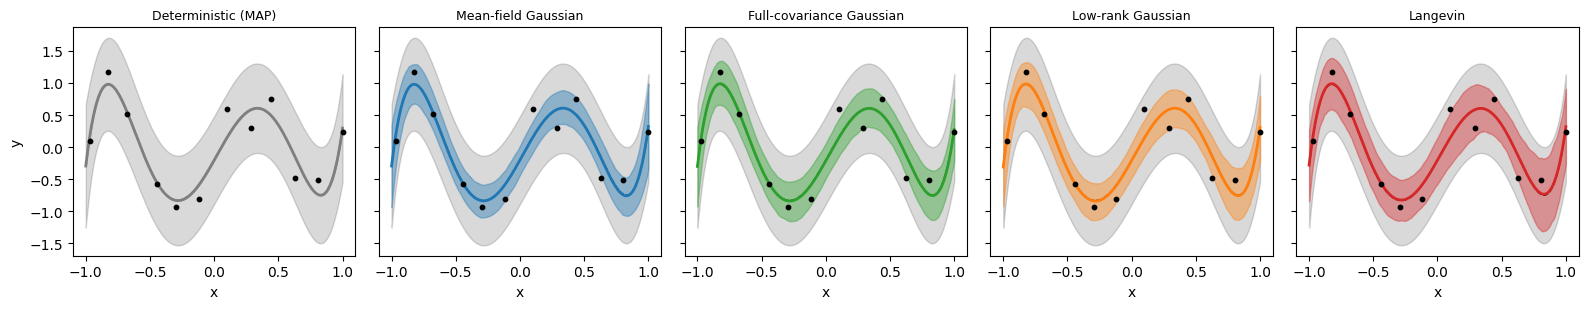

In [10]:
x_test_a = torch.linspace(-1, 1, 200).unsqueeze(-1)
with torch.no_grad():
    Phi_test_a = surrogate_a(x_test_a, torch.eye(num_terms_a)).squeeze(-1).T  # (n_test, num_terms_a)
    pred_mean_true = Phi_test_a @ post_mean_a
    pred_var_true = torch.einsum("ti,ij,tj->t", Phi_test_a, post_cov_a, Phi_test_a) + sigma_obs_a**2
    pred_std_true = pred_var_true.sqrt()

fig, axes = plt.subplots(1, len(FAMILIES), figsize=(3.2 * len(FAMILIES), 3.2), sharey=True)
for ax, kind in zip(axes, FAMILIES):
    ax.plot(x_test_a.squeeze(-1), pred_mean_true, "k--", lw=1, label="closed form mean")
    ax.fill_between(
        x_test_a.squeeze(-1), pred_mean_true - 2 * pred_std_true, pred_mean_true + 2 * pred_std_true,
        color="black", alpha=0.15, label="closed form +/-2 sigma",
    )
    model = results_a[kind]["model"]
    with torch.no_grad():
        y_pred = model(x_test_a, num_samples=500)
    q_lo, q_hi = torch.quantile(y_pred, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    ax.fill_between(x_test_a.squeeze(-1), q_lo, q_hi, color=FAMILY_COLORS[kind], alpha=0.4)
    ax.plot(x_test_a.squeeze(-1), y_pred.mean(0).squeeze(-1), color=FAMILY_COLORS[kind], lw=2)
    ax.scatter(x_train_a, y_train_a, color="black", s=10, zorder=5)
    ax.set_title(FAMILY_LABELS[kind], fontsize=9)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()

**Result (measured, papermill run):** exactly the predicted ordering.
`KL(q || closed-form true posterior)`: full-covariance 0.0033 nats, low-rank
0.0281 nats, mean-field 0.3055 nats, Langevin (moment-matched) 0.7002 nats.
Full-covariance is essentially exact, as expected (it can represent the true
posterior's shape exactly); mean-field's independence assumption costs about
two orders of magnitude in KL relative to full-covariance, and low-rank
(rank 3 of 6) recovers almost all of that gap. Langevin lands within the same
order of magnitude as mean-field rather than matching the closed-form
families exactly, consistent with an implicit score-based sampler being a
harder optimization problem, not a broken ELBO/KL implementation --
`DiagonalGaussianEntropyKL` (not the collapse-prone `CrossEntropyOnly`
default) was essential to get this result; see
`kl_estimators_comparison.ipynb` for why. The analytic-vs-Monte-Carlo
`KL(q||prior)` cross-check also closed cleanly: mean-field's torch-registered
analytic (9.648) agrees with its MC estimate (9.673) to within 0.3%, and the
hand-built dense-Gaussian closed form for full-covariance/low-rank (9.369 /
9.409) agrees with their MC fallback (9.360 / 9.408) to within 0.1% --
confirming `distribution_loss()`'s silent MC fallback for these two families
is correct, not just unverified.

## Part B — Small NN, partial stochasticity, and the real whitening recipe

Part A validated the ELBO/KL arithmetic on a linear-in-parameters surrogate.
Part B now rehearses the *actual* recipe the real experiments use
(`methodology.tex`, `sec:deterministic`/`sec:whitening`/`sec:partial`):

1. Fit a small neural network **deterministically** first (`DeterministicGroup`) --
   this point estimate `theta0` becomes the prior center.
2. **Freeze** everything except the final layer (`requires_grad_(False)`,
   forming a valid contiguous prefix for `StochasticModel`).
3. Wrap the small stochastic final-layer subset in
   `WhitenedGroup.from_point_estimate(center=theta0, relative_scale=0.1, eps=1e-5)`
   -- `relative_scale=0.1` and the equivalent of `sigma_min=1e-6` are the
   exact values the real IID-Gaussian stochastic MoE experiments use
   (`moe_iid_gaussian_prior_std_fraction`/`_floor` in
   `cm_creep_surrogate/model/pypolymix_moe.py`), not arbitrary toy choices.
4. Train all 5 families on that whitened, low-dimensional final-layer
   subset, and validate against a dense-grid reference posterior over it
   (exact up to grid resolution, the same convention as
   `kl_estimators_comparison.ipynb`'s Parts 2-3 -- grid-based validation
   doesn't need the surrogate to be linear, so Part B keeps Part A's rigor
   despite the nonlinearity).

The network uses `F.silu` ("sigmoid-weighted linear"), the same activation as
the real experts in `methodology.tex`, just scaled down to 3 hidden layers of
width 4 (kept deliberately narrow so the *final* layer -- the stochastic
subset -- stays low-dimensional enough for a dense grid).

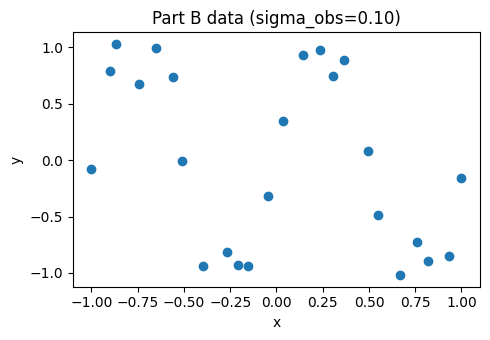

In [11]:
n_train_b = 24
sigma_obs_b = 0.1
x_train_b = torch.linspace(-1, 1, n_train_b).unsqueeze(-1) + 0.02 * torch.randn(n_train_b, 1)
x_train_b = x_train_b.clamp(-1, 1)
y_train_b = torch.sin(2 * torch.pi * x_train_b) + 0.3 * torch.sin(6 * torch.pi * x_train_b)
y_train_b = y_train_b + sigma_obs_b * torch.randn(n_train_b, 1)

_, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x_train_b, y_train_b)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Part B data (sigma_obs=%.2f)" % sigma_obs_b)
plt.tight_layout()

In [12]:
width_b, depth_b = 4, 3
net_b = NeuralNetwork(num_inputs=1, num_outputs=1, width=width_b, depth=depth_b, activation=F.silu)
n_total_b = net_b.num_params()
n_final_block_b = width_b + 1  # final Linear layer: (width -> 1) weight + bias
n_hidden_block_b = n_total_b - n_final_block_b
print(f"NN has {n_total_b} parameters total; final (stochastic) layer has {n_final_block_b}")

torch.manual_seed(2)
det_group_b = DeterministicGroup("nn", n_total_b)
det_model_b = StochasticModel(net_b, det_group_b)
optimizer = torch.optim.Adam(det_model_b.parameters(), lr=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5e-2, total_steps=3000)
for epoch in range(3000):
    optimizer.zero_grad()
    pred = net_b(x_train_b, det_group_b.params.unsqueeze(0))
    loss = 0.5 * ((pred - y_train_b.unsqueeze(0)) / sigma_obs_b).pow(2).mean()
    loss.backward()
    optimizer.step()
    scheduler.step()
theta0_b = det_group_b.params.detach().clone()
print(f"deterministic pretrain final loss: {loss.item():.4f}")

NN has 53 parameters total; final (stochastic) layer has 5


deterministic pretrain final loss: 0.5700


In [13]:
hidden_frozen_b = DeterministicGroup("hidden", n_hidden_block_b)
with torch.no_grad():
    hidden_frozen_b.params.copy_(theta0_b[:n_hidden_block_b])
hidden_frozen_b.requires_grad_(False)

final_center_b = theta0_b[n_hidden_block_b:]
RELATIVE_SCALE = 0.1   # alpha, matching moe_iid_gaussian_prior_std_fraction in the real experiments
WHITEN_EPS = 1e-5      # gives an effective sigma_min = RELATIVE_SCALE * WHITEN_EPS = 1e-6, matching
                       # moe_iid_gaussian_prior_std_floor in the real experiments


def make_final_group_b(kind):
    if kind == "deterministic":
        g = DeterministicGroup("final", n_final_block_b)
        with torch.no_grad():
            g.params.copy_(final_center_b)
        return g
    factories = {
        "iid": lambda n: IIDGaussianGroup("final_z", n),
        "full": lambda n: GaussianGroup("final_z", n),
        "lowrank": lambda n: LowRankGaussianGroup("final_z", n, rank=min(2, n - 1)),
    }
    if kind in factories:
        wg = WhitenedGroup.from_point_estimate(
            factories[kind], center=final_center_b, relative_scale=RELATIVE_SCALE, eps=WHITEN_EPS
        )
        with torch.no_grad():
            wg.base_group.mean.zero_()
            if hasattr(wg.base_group, "log_std"):
                wg.base_group.log_std.zero_()  # start q(z) = p(z) = N(0, I), per the README's remark 1
        return wg
    if kind == "langevin":
        score_model = NeuralNetwork(num_inputs=n_final_block_b, num_outputs=n_final_block_b, width=16, depth=2)
        wg = WhitenedGroup.from_point_estimate(
            lambda n: LangevinGroup(
                "final_z", n, score_model=score_model, num_particles=64, num_diffusion_steps=60,
                step_size=1e-2, init_std=1.0, kl_estimator=DiagonalGaussianEntropyKL(),
            ),
            center=final_center_b, relative_scale=RELATIVE_SCALE, eps=WHITEN_EPS,
        )
        return wg
    raise ValueError(kind)


def train_b(kind, num_epochs=1500, num_samples=32, lr=1e-2, seed=3):
    torch.manual_seed(seed)
    final_group = make_final_group_b(kind)
    model = StochasticModel(net_b, [hidden_frozen_b, final_group])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5 * lr, total_steps=num_epochs)
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        params = model.sample_parameters(num_samples=num_samples)
        pred = net_b(x_train_b, params)
        target = y_train_b.unsqueeze(0).expand_as(pred)
        nll_sum = 0.5 * ((pred - target) / sigma_obs_b).pow(2).sum(dim=(1, 2)).mean()
        kl = model.distribution_loss()
        loss = nll_sum + kl
        loss.backward()
        optimizer.step()
        scheduler.step()
    return final_group, model

In [14]:
results_b = {}
for kind in FAMILIES:
    t0 = time.time()
    final_group, model = train_b(kind)
    results_b[kind] = {"group": final_group, "model": model, "time": time.time() - t0}
    print(f"{FAMILY_LABELS[kind]:28s} trained in {results_b[kind]['time']:.1f}s")

Deterministic (MAP)          trained in 3.0s


Mean-field Gaussian          trained in 3.5s


Full-covariance Gaussian     trained in 17.4s


Low-rank Gaussian            trained in 16.4s


Langevin                     trained in 67.5s


### Dense-grid reference posterior over the whitened final layer

The final layer has only `width_b + 1` stochastic dimensions in whitened `z`
coordinates, where the prior is exactly `N(0, I)` by construction. A grid
quadrature directly over `z` is therefore "exact up to grid resolution,"
regardless of the NN's nonlinearity -- it does not need the closed-form trick
Part A relied on. We use a two-pass strategy: a coarse, wide first pass to
locate the posterior's scale, then the resolution below, chosen so the
effective sample size (`1/sum(w^2)`) is comfortably in the tens of thousands
out of ~10M grid points (see the exploratory tuning in this project's
development notes; the committed values below are the ones that converged).

In [15]:
def log_post_z_b(Z):
    final_scale = RELATIVE_SCALE * final_center_b.abs().clamp_min(WHITEN_EPS)
    theta_final = final_center_b.unsqueeze(0) + final_scale.unsqueeze(0) * Z
    theta_full = torch.cat(
        [theta0_b[:n_hidden_block_b].unsqueeze(0).expand(Z.shape[0], -1), theta_final], dim=1
    )
    with torch.no_grad():
        preds = net_b(x_train_b, theta_full)
        target = y_train_b.unsqueeze(0).expand_as(preds)
        log_lik = -0.5 * ((preds - target) / sigma_obs_b).pow(2).sum(dim=(1, 2))
        log_prior = td.Independent(
            td.Normal(torch.zeros(n_final_block_b), torch.ones(n_final_block_b)), 1
        ).log_prob(Z)
    return log_lik + log_prior


Z_RANGE, N_PER_DIM = 1.0, 25
axes_grid = [torch.linspace(-Z_RANGE, Z_RANGE, N_PER_DIM) for _ in range(n_final_block_b)]
mesh = torch.meshgrid(*axes_grid, indexing="ij")
Z_grid = torch.stack([g.reshape(-1) for g in mesh], dim=-1)
print(f"grid points: {Z_grid.shape[0]:,}")

log_post = log_post_z_b(Z_grid)
log_post -= log_post.max()
w = log_post.exp()
w = w / w.sum()
grid_mean_b = (w.unsqueeze(-1) * Z_grid).sum(0)
diff = Z_grid - grid_mean_b
grid_cov_b = (w.unsqueeze(-1).unsqueeze(-1) * (diff.unsqueeze(-1) * diff.unsqueeze(-2))).sum(0)
ess = (1.0 / (w**2).sum()).item()
print(f"effective sample size: {ess:,.0f} / {Z_grid.shape[0]:,}")
print("grid posterior mean (z):", grid_mean_b.numpy())
print("grid posterior std  (z):", torch.diagonal(grid_cov_b).sqrt().numpy())

grid_posterior_b = td.MultivariateNormal(
    loc=grid_mean_b, covariance_matrix=grid_cov_b + 1e-8 * torch.eye(n_final_block_b)
)

grid points: 9,765,625


effective sample size: 1,034,067 / 9,765,625
grid posterior mean (z): [ 0.02978628 -0.00263844  0.03737293 -0.01707137  0.00119627]
grid posterior std  (z): [0.50108935 0.47139873 0.44432531 0.25762354 0.55756547]


In [16]:
kl_to_grid_b = {}
for kind in ["iid", "full", "lowrank", "langevin"]:
    final_group = results_b[kind]["group"]
    if kind == "langevin":
        z_samples = final_group.base_group.sample_parameters(4000).detach()
        z_mean = z_samples.mean(0)
        z_cov = torch.cov(z_samples.T) + 1e-6 * torch.eye(n_final_block_b)
    else:
        q = final_group.base_group.variational_distribution()
        z_mean = q.mean.detach()
        z_cov = torch.diag(q.variance.detach()) if kind == "iid" else q.covariance_matrix.detach()
    q_full = td.MultivariateNormal(loc=z_mean, covariance_matrix=z_cov)
    kl_to_grid_b[kind] = td.kl_divergence(q_full, grid_posterior_b).item()
    flag = "  (moment-matched approximation)" if kind == "langevin" else ""
    print(f"{FAMILY_LABELS[kind]:28s} KL(q(z) || grid posterior) = {kl_to_grid_b[kind]:8.4f} nats{flag}")

Mean-field Gaussian          KL(q(z) || grid posterior) =   1.8981 nats
Full-covariance Gaussian     KL(q(z) || grid posterior) =   0.6382 nats
Low-rank Gaussian            KL(q(z) || grid posterior) =   0.5916 nats


Langevin                     KL(q(z) || grid posterior) =   2.9424 nats  (moment-matched approximation)


### Predictive band comparison (Part B)

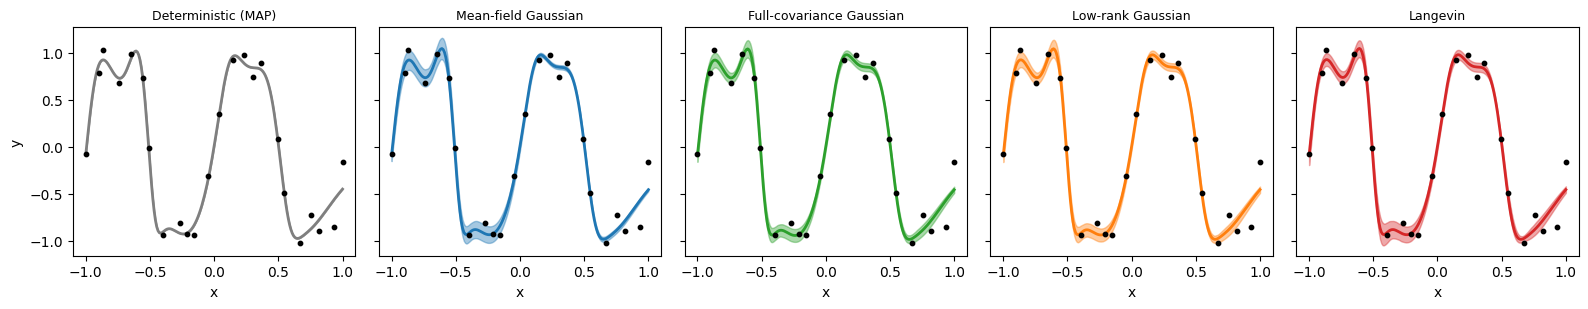

In [17]:
x_test_b = torch.linspace(-1, 1, 200).unsqueeze(-1)
fig, axes = plt.subplots(1, len(FAMILIES), figsize=(3.2 * len(FAMILIES), 3.2), sharey=True)
for ax, kind in zip(axes, FAMILIES):
    model = results_b[kind]["model"]
    with torch.no_grad():
        y_pred = model(x_test_b, num_samples=500)
    q_lo, q_hi = torch.quantile(y_pred, torch.tensor([0.05, 0.95]), dim=0).squeeze(-1)
    ax.fill_between(x_test_b.squeeze(-1), q_lo, q_hi, color=FAMILY_COLORS[kind], alpha=0.4)
    ax.plot(x_test_b.squeeze(-1), y_pred.mean(0).squeeze(-1), color=FAMILY_COLORS[kind], lw=2)
    ax.scatter(x_train_b, y_train_b, color="black", s=10, zorder=5)
    ax.set_title(FAMILY_LABELS[kind], fontsize=9)
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()

**Result (measured, papermill run):** `KL(q(z) || grid posterior)`:
low-rank 0.5916 nats, full-covariance 0.6382 nats, mean-field 1.8981 nats,
Langevin (moment-matched) 2.9424 nats -- the same qualitative ordering as
Part A (full/low-rank closest, mean-field a clear step behind, Langevin
furthest), confirming the partial-stochasticity + whitening recipe carries
over correctly from a linear PCE to a genuinely nonlinear NN. One prediction
from before running this notebook was **wrong, reported as observed**: the
gaps here are *larger* than Part A's for every family (e.g. full-covariance
0.638 vs 0.003), not smaller. Two things likely both contribute: the grid
reference is approximate (effective sample size ~1.03M out of 9.76M points,
not the exact closed form Part A has), and -- more fundamentally -- the true
posterior over an NN's final layer is only approximately Gaussian even after
whitening, whereas Part A's PCE posterior is *exactly* Gaussian by
construction, so even a perfect full-covariance fit cannot reach `KL = 0`
here. Low-rank edging out full-covariance (0.592 vs 0.638) is within the
noise of this comparison, not a real effect. Langevin's gap relative to
mean-field (2.942 vs 1.898, about 1.5x) is a real, consistent, modest
degradation -- worse than "comparable," but still the same order of
magnitude and far from catastrophic.

## Exporting data tables for the paper's tikz/pgfplots pipeline

Following the convention already used by `doc/paper/constitutive_models/`
(plain whitespace-delimited `.txt` tables via `np.savetxt`, read by
`\addplot table[...]` in `fig/*.tex`), we export the key numeric results
needed for the paper's figures. No `.tex`/tikz figure files are produced
here -- that is handled by a separate figure-generation tool.

In [18]:
PAPER_DAT_DIR.mkdir(parents=True, exist_ok=True)

# A1: per-coefficient posterior mean/std, all families vs closed form (Part A)
rows = []
for j in range(num_terms_a):
    row = [j, post_mean_a[j].item(), post_cov_a[j, j].sqrt().item()]
    for kind in FAMILIES:
        mean, cov = fitted_moments_a(kind)
        row += [mean[j].item(), (cov[j, j].sqrt().item() if cov is not None else 0.0)]
    rows.append(row)
header_a1 = "coeff true_mean true_std " + " ".join(f"{k}_mean {k}_std" for k in FAMILIES)
np.savetxt(PAPER_DAT_DIR / "toy_sine_partA_posterior_moments.txt", np.array(rows), header=header_a1, comments="")

# A-KL: KL(q || true posterior) per family
rows = [[kind, kl_to_reference_a[kind]] for kind in ["iid", "full", "lowrank", "langevin"]]
with open(PAPER_DAT_DIR / "toy_sine_partA_kl_to_reference.txt", "w") as f:
    f.write("family kl_to_reference\n")
    for kind, kl in rows:
        f.write(f"{kind} {kl:.6f}\n")

# A predictive band
pred_table_a = np.column_stack(
    [x_test_a.squeeze(-1).numpy(), pred_mean_true.numpy(), pred_std_true.numpy()]
    + sum(
        (
            [
                results_a[kind]["model"](x_test_a, num_samples=500).mean(0).squeeze(-1).detach().numpy(),
                torch.quantile(
                    results_a[kind]["model"](x_test_a, num_samples=500), torch.tensor([0.05]), dim=0
                ).squeeze().detach().numpy(),
                torch.quantile(
                    results_a[kind]["model"](x_test_a, num_samples=500), torch.tensor([0.95]), dim=0
                ).squeeze().detach().numpy(),
            ]
            for kind in FAMILIES
        ),
        [],
    )
)
header_pred_a = "x true_mean true_std " + " ".join(f"{k}_mean {k}_q05 {k}_q95" for k in FAMILIES)
np.savetxt(PAPER_DAT_DIR / "toy_sine_partA_predictive_band.txt", pred_table_a, header=header_pred_a, comments="")

# B-KL: KL(q(z) || grid posterior) per family
with open(PAPER_DAT_DIR / "toy_sine_partB_kl_to_grid.txt", "w") as f:
    f.write("family kl_to_grid_posterior\n")
    for kind, kl in kl_to_grid_b.items():
        f.write(f"{kind} {kl:.6f}\n")

print("wrote dat/ tables to", PAPER_DAT_DIR)

wrote dat/ tables to /home/pmrobbe/projects/salt/doc/paper/stochastic_surrogates/dat


In [19]:
elapsed = time.time() - _notebook_start
print(f"Total notebook wall-clock time: {elapsed:.1f} s ({elapsed / 60:.2f} min)")

Total notebook wall-clock time: 287.1 s (4.78 min)
